# Task 2 – Image Data Collection and Processing

**Owner:** Shema
**Reads:** `data/images/raw/<member>/<member>_<expression>.jpg` (3 photos per member: neutral, smiling, surprised)
**Writes:** `data/images/augmented/…` and `data/cleaned_data/image_features.csv`

**Plan**
1. Check every member submitted the 3 required photos (consistent naming).
2. Display the photos.
3. Crop the face out of each photo.
4. Make **4 augmentations** per photo (rotation, flip, grayscale, brightness).
5. Extract features (HOG + LBP histogram + colour histogram) and save them.

All the processing code lives in `src/image_pipeline.py`. This notebook calls it and shows each step, so the notebook, the training script and the command-line app all use **exactly the same** processing.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))   # reuse the project code in src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as C

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
from image_pipeline import (list_raw_images, missing_images_report, load_image,
                            detect_and_crop_face, augment, extract_features, build_image_features)
from skimage.feature import hog, local_binary_pattern
import cv2

## 1. Check that every member submitted all 3 expressions

In [2]:
raw = list_raw_images()
print("Photos found:", len(raw))
display(raw.assign(file=raw.path.map(lambda p: p.name)).pivot_table(index="member", columns="expression", values="file", aggfunc="first"))

missing = missing_images_report()
print("Missing:", missing if missing else "none - every member has neutral, smiling and surprised")

Photos found: 9


expression,neutral,smiling,surprised
member,,,
peggy,peggy_neutral.jpg,peggy_smiling.jpg,peggy_surprised.jpg
santhiana,santhiana_neutral.jpeg,santhiana_smiling.jpeg,santhiana_surprised.jpeg
shema,Shema_neutral.jpeg,shema_smiling.jpeg,Shema_surprised.jpeg


Missing: ['jonathan/jonathan_neutral.jpg', 'jonathan/jonathan_smiling.jpg', 'jonathan/jonathan_surprised.jpg']


**Result:** 9 of the 12 required photos are in: Peggy, Santhiana and Shema each have all three expressions. **Jonathan's three photos are still missing.**

**Naming check:** Santhiana and Shema used `.jpeg` instead of `.jpg`, and Shema's folder and two of his files start with a capital S (`Shema_neutral.jpeg`). The pipeline lower-cases names and accepts both extensions, so nothing breaks. For the rubric's "consistent naming and format", the files should still be renamed to `<member>_<expression>.jpg` in lower case.

**Naming convention:** `data/images/raw/<member>/<member>_<expression>.jpg`, in lower case. The folder name gives the label (who it is), and the file name gives the expression. That way nobody has to type labels by hand, and the table above shows straight away when a photo is missing.

## 2. Display sample pictures of each member

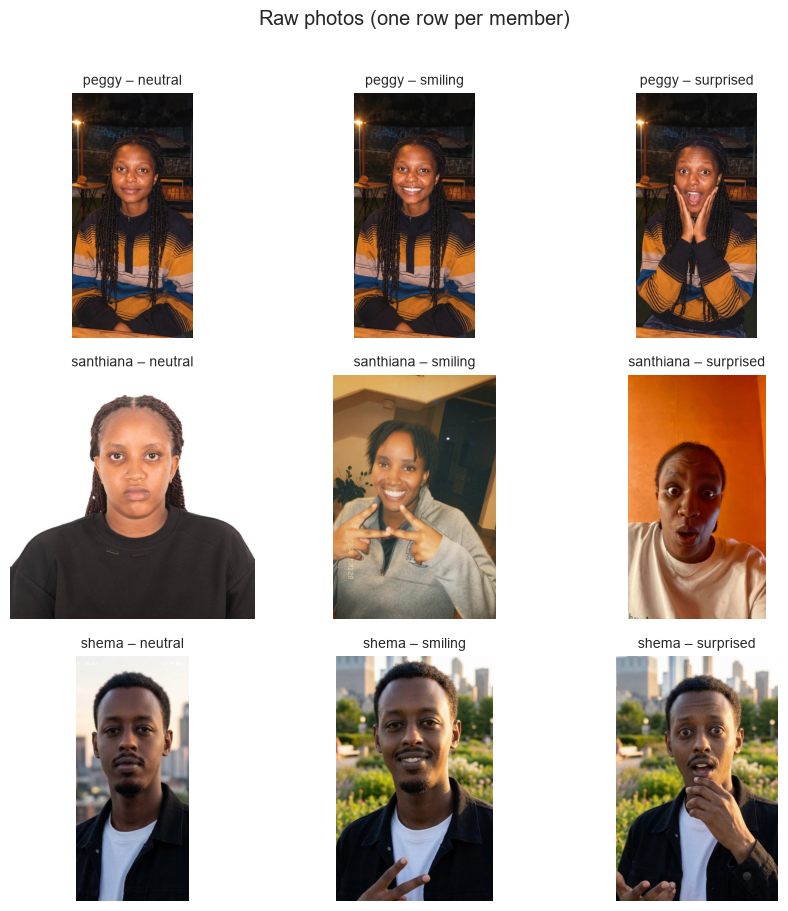

In [3]:
members = sorted(raw.member.unique())
fig, axes = plt.subplots(len(members), len(C.EXPRESSIONS), figsize=(3 * len(C.EXPRESSIONS), 3 * len(members)), squeeze=False)
for i, m in enumerate(members):
    for j, e in enumerate(C.EXPRESSIONS):
        ax = axes[i, j]; ax.axis("off")
        row = raw[(raw.member == m) & (raw.expression == e)]
        if not row.empty:
            ax.imshow(load_image(row.path.iloc[0]))
        ax.set_title(f"{m} – {e}", fontsize=10)
plt.suptitle("Raw photos (one row per member)", y=1.01); plt.tight_layout(); plt.show()

**What the photos show:**
- **Peggy:** all three photos were taken in one evening, at the same outdoor table, in the same sweater.
- **Santhiana:** three different places and lights (a white wall, a beige indoor room, an orange wall).
- **Shema:** outdoors with a city and park background.

Every expression is clearly different from the neutral one. The variety in Santhiana's photos matters later: it makes her the hardest member for the face model, because one of her photos never looks much like the other two.

## 3. Find and crop the face

**Decision:** before extracting features, we cut out just the face with OpenCV's Haar-cascade face detector, then resize it to **128×128**.

**Why:**
- Photos are taken on different phones, at different distances and against different backgrounds. Without cropping, the model could learn "white wall = Peggy" instead of the face itself.
- A fixed size makes every feature vector the same length.
- The photo's EXIF rotation is applied first, because phone photos are often stored sideways.
- If no face is found, the code falls back to a centre crop, so the pipeline never crashes. That case is reported below.

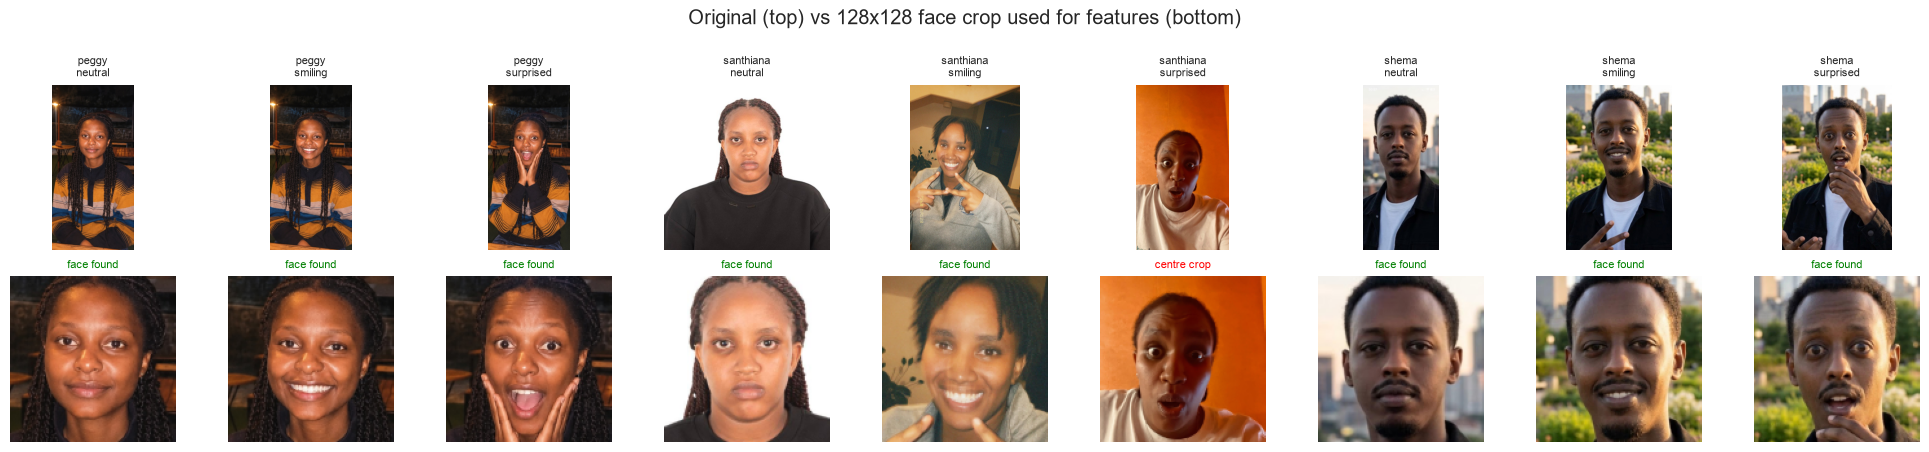

In [4]:
fig, axes = plt.subplots(2, len(raw), figsize=(2.2 * len(raw), 4.6), squeeze=False)
for k, r in enumerate(raw.itertuples()):
    img = load_image(r.path); face, found = detect_and_crop_face(img)
    axes[0, k].imshow(img); axes[0, k].set_title(f"{r.member}\n{r.expression}", fontsize=8)
    axes[1, k].imshow(face); axes[1, k].set_title("face found" if found else "centre crop", fontsize=8,
                                                 color="green" if found else "red")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Original (top) vs 128x128 face crop used for features (bottom)"); plt.tight_layout(); plt.show()

**Result:** the Haar detector found the face in **8 of 9** photos. For `santhiana_surprised.jpeg` it found none and fell back to the centre crop. That crop still contains her whole face, slightly smaller and off-centre, so the photo is still usable.

## 4. Augmentations (4 per photo)

| Augmentation | What it simulates | Why it helps |
|---|---|---|
| `rotate_15` | head tilted 15° | people rarely hold their head perfectly straight |
| `flip` | mirror image | a selfie camera mirrors the picture; a face is still the same person |
| `grayscale` | colour removed | stops the model relying only on skin, clothing or background colour |
| `brightness` | brighter and more contrast | different lighting (window vs indoor lamp) |

**Why augment at all:** we only have 3 photos per person, which is far too few to learn from. Each augmentation gives a realistic new version of the same face, so we get **5×** the training rows.

**Why these four and not more extreme ones:** a heavy blur or a 90° rotation would produce images the system will never see when someone actually logs in.

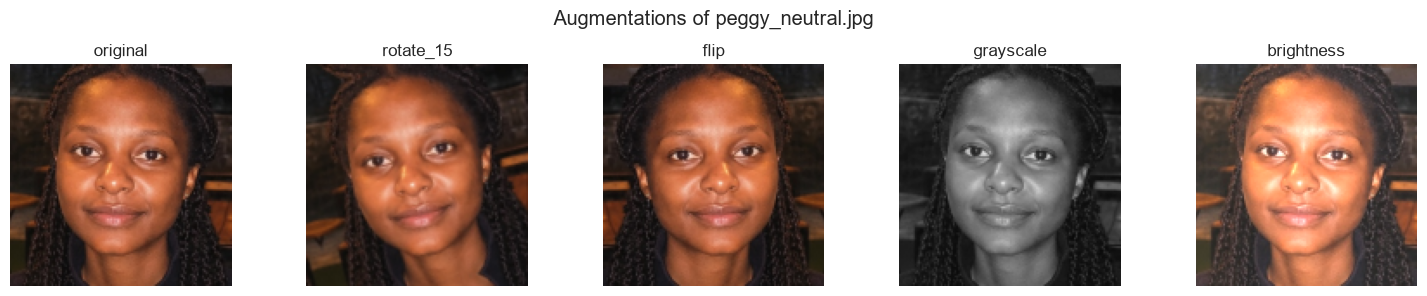

In [5]:
example = raw.iloc[0]
face, _ = detect_and_crop_face(load_image(example.path))
versions = {"original": face, **augment(face)}
fig, axes = plt.subplots(1, len(versions), figsize=(3 * len(versions), 3))
for ax, (name, img) in zip(axes, versions.items()):
    ax.imshow(img); ax.set_title(name); ax.axis("off")
plt.suptitle(f"Augmentations of {example.path.name}"); plt.tight_layout(); plt.show()

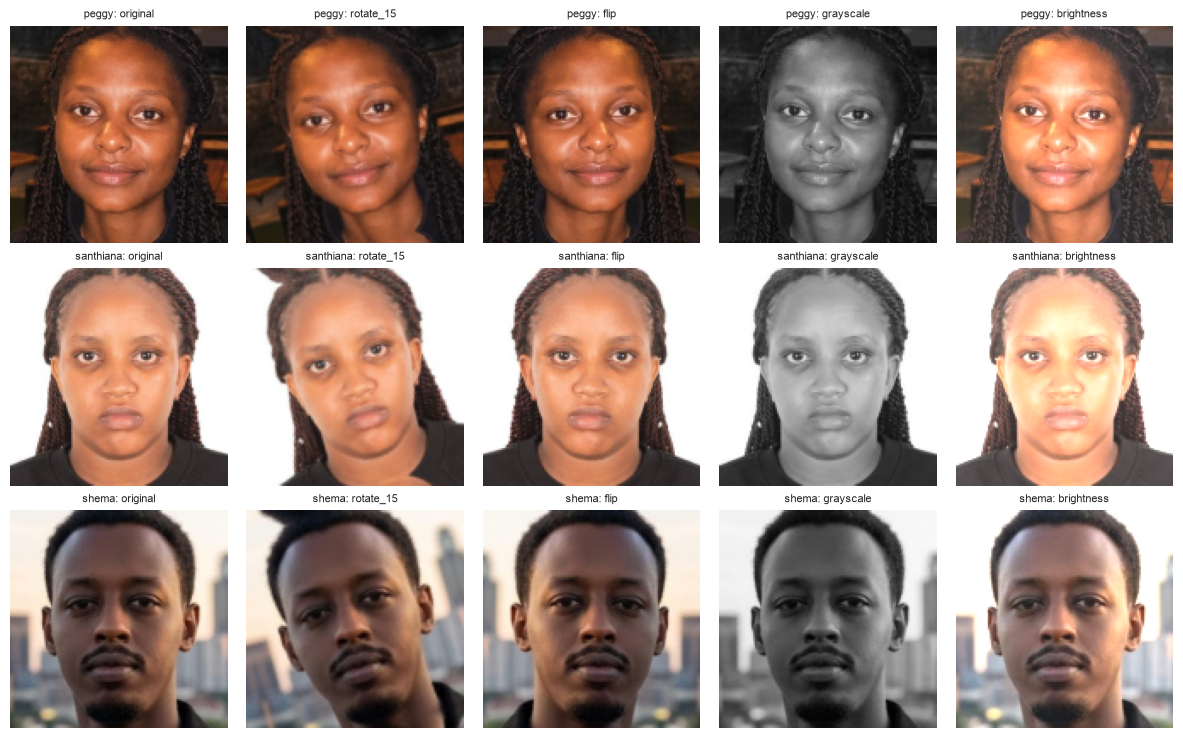

In [6]:
# every member: the 4 augmentations of their neutral photo
neutral = raw[raw.expression == "neutral"]
fig, axes = plt.subplots(len(neutral), 5, figsize=(12, 2.5 * len(neutral)), squeeze=False)
for i, r in enumerate(neutral.itertuples()):
    face, _ = detect_and_crop_face(load_image(r.path))
    for j, (name, img) in enumerate({"original": face, **augment(face)}.items()):
        axes[i, j].imshow(img); axes[i, j].axis("off"); axes[i, j].set_title(f"{r.member}: {name}", fontsize=8)
plt.tight_layout(); plt.show()

**Result:** each photo now has 4 extra versions. The rotated and brightened copies keep the colours, the grayscale copy removes them, and the flip mirrors the face. All 4 are still clearly the same person.

## 5. Feature extraction

Each face (original or augmented) is turned into **358 numbers**:

| Feature | Size | What it captures |
|---|---|---|
| **HOG** (Histogram of Oriented Gradients) | 324 | The **shape** of the face: the direction of edges around the eyes, nose, mouth and jaw. We use large 32×32-pixel cells so the vector stays small, because we have tens of images, not thousands. |
| **LBP histogram** (Local Binary Patterns) | 10 | **Texture**: skin, beard, glasses frames. |
| **Colour histogram** | 24 (8 bins × R, G, B) | **Skin tone and hair colour**. |

**Decision: hand-crafted features instead of a deep face embedding (such as FaceNet).**
- Deep-learning libraries (TensorFlow/PyTorch) are large and don't install reliably on our Python version.
- The assignment explicitly allows *"embeddings, histograms"*.
- Every number here can be explained.
- The three groups complement each other: shape, texture and colour.

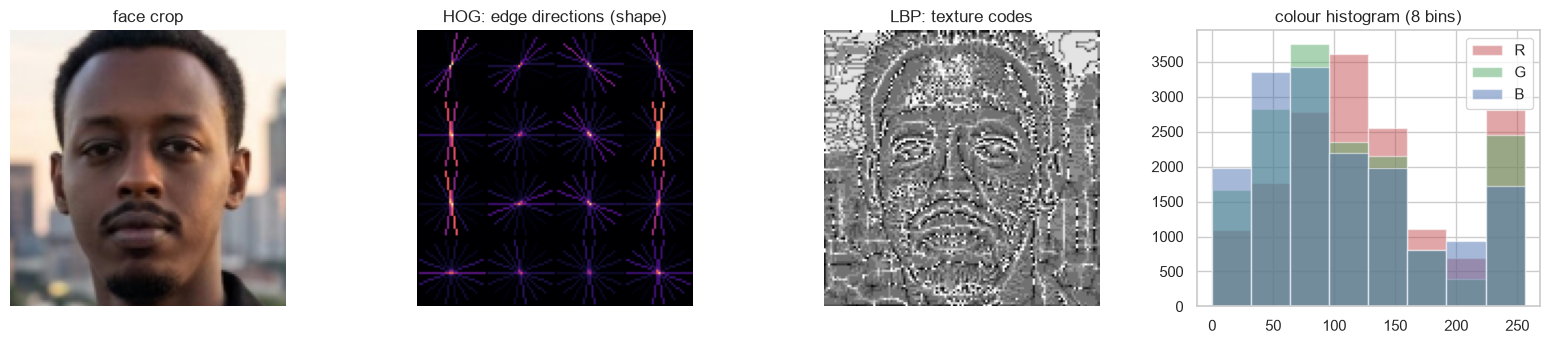

In [7]:
gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
_, hog_img = hog(gray, orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2), visualize=True)
lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(face); axes[0].set_title("face crop")
axes[1].imshow(hog_img, cmap="magma"); axes[1].set_title("HOG: edge directions (shape)")
axes[2].imshow(lbp, cmap="gray"); axes[2].set_title("LBP: texture codes")
for ch, col in enumerate("rgb"):
    axes[3].hist(face[..., ch].ravel(), bins=8, range=(0, 256), alpha=0.5, color=col, label=col.upper())
axes[3].set_title("colour histogram (8 bins)"); axes[3].legend()
for ax in axes[:3]: ax.axis("off")
plt.tight_layout(); plt.show()

In [8]:
features = build_image_features()        # saves augmented images + image_features.csv
features.iloc[:, :10].head(10)

  ! no face detected in santhiana_surprised.jpeg -> used centre crop
9 photos x 5 versions = 45 rows, 358 features -> C:\Users\PeggyDusenge\Desktop\U\UserIdentityandProductRecommendationSystem\data\cleaned_data\image_features.csv


,member,expression,augmentation,source_image,face_detected,hog_0,hog_1,hog_2,hog_3,hog_4
0,peggy,neutral,original,peggy/peggy_neutral.jpg,1,0.142375,0.155935,0.122370,0.148805,0.210834
1,peggy,neutral,rotate_15,peggy/peggy_neutral.jpg,1,0.211674,0.212324,0.162394,0.127250,0.128247
2,peggy,neutral,flip,peggy/peggy_neutral.jpg,1,0.160959,0.212819,0.224876,0.155765,0.215615
3,peggy,neutral,grayscale,peggy/peggy_neutral.jpg,1,0.142375,0.155935,0.122370,0.148805,0.210834
4,peggy,neutral,brightness,peggy/peggy_neutral.jpg,1,0.149913,0.152327,0.140373,0.150128,0.220074
5,peggy,smiling,original,peggy/peggy_smiling.jpg,1,0.159549,0.102538,0.073204,0.123149,0.227510
6,peggy,smiling,rotate_15,peggy/peggy_smiling.jpg,1,0.196802,0.142814,0.130649,0.108505,0.094012
7,peggy,smiling,flip,peggy/peggy_smiling.jpg,1,0.169438,0.208642,0.202275,0.171041,0.172570
8,peggy,smiling,grayscale,peggy/peggy_smiling.jpg,1,0.159549,0.102538,0.073204,0.123149,0.227510
9,peggy,smiling,brightness,peggy/peggy_smiling.jpg,1,0.176405,0.100158,0.083932,0.130928,0.236590


In [9]:
print("Rows per member:"); print(features.member.value_counts().to_string())
print("\nRows per augmentation:"); print(features.augmentation.value_counts().to_string())
print("\nMissing values:", features.isna().sum().sum())
print("Faces detected:", int(features.query("augmentation == 'original'").face_detected.sum()), "of", len(raw))

Rows per member:
member
peggy        15
santhiana    15
shema        15

Rows per augmentation:
augmentation
original      9
rotate_15     9
flip          9
grayscale     9
brightness    9

Missing values: 0
Faces detected: 8 of 9


**Result:** 9 photos × 5 versions = **45 rows**, 15 per member and 9 per augmentation, with **358 features** each and **no missing values**. The file is saved as `data/cleaned_data/image_features.csv`.

## 6. Do the features separate the members?

A 2-D PCA projection squeezes the 358 features down to 2 so we can look at them. If the points of each member form their own cloud, the face model has something to learn from.

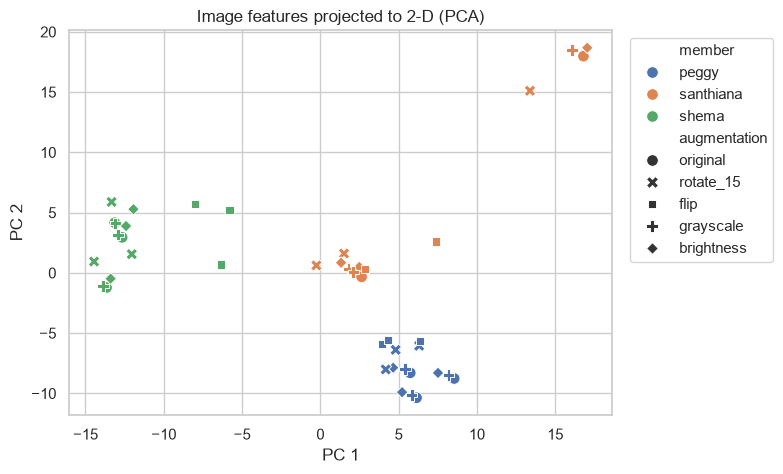

In [10]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from identity_model import feature_columns

Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(features[feature_columns(features)]))
plt.figure(figsize=(7, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=features.member, style=features.augmentation, s=70)
plt.title("Image features projected to 2-D (PCA)"); plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

**What it shows:**
- **The three members form three separate clouds,** so the features clearly carry identity information. Shema is on the left, Peggy at the bottom right, and Santhiana in the middle.
- **Peggy's points are the tightest:** all her photos share one scene and light.
- **Santhiana's points are spread widest:** one group sits apart at the top right, which is one of her very differently lit photos (the orange wall). This matches the face model's results, where her held-out photos are the hardest.
- **Flipped copies sometimes land away from their originals** (Shema's squares, for example). HOG records the direction of edges, so a mirrored face gives different edge directions. That's the variety the augmentation is meant to add.

## Summary
- Every member's 3 expressions were loaded and displayed, using consistent naming.
- Faces were cropped to 128×128, and **4 augmentations** were made for each photo.
- **358 features** per image (HOG + LBP + colour histogram) were saved to `data/cleaned_data/image_features.csv`, along with the labels `member, expression, augmentation, source_image`.

**Next:** `training_models/face_model_training.ipynb`.